HELLO


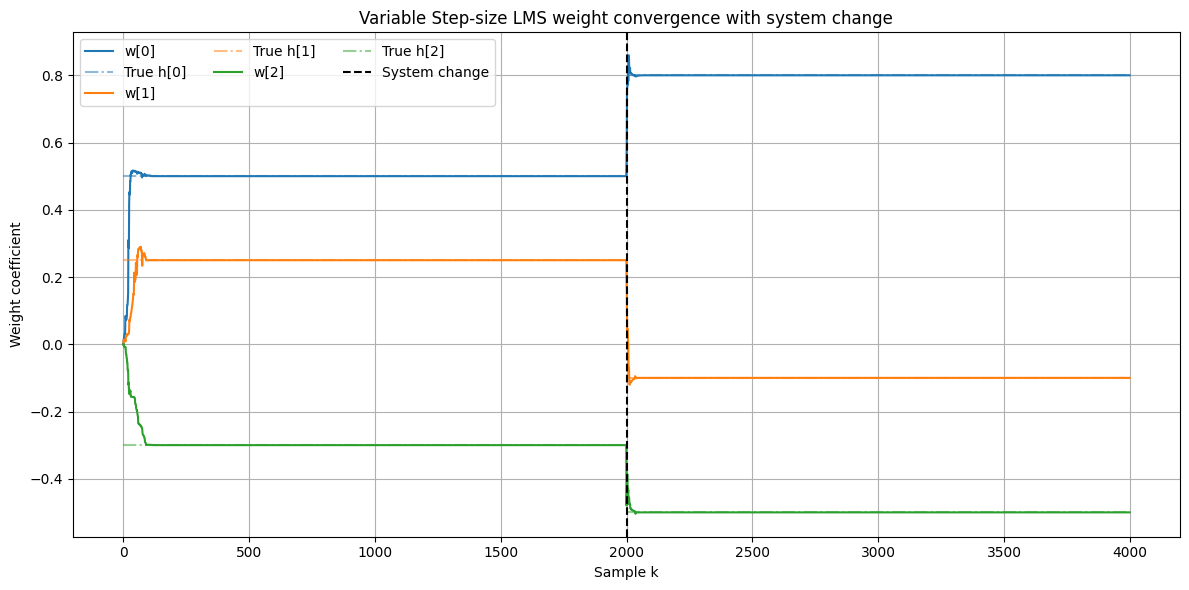

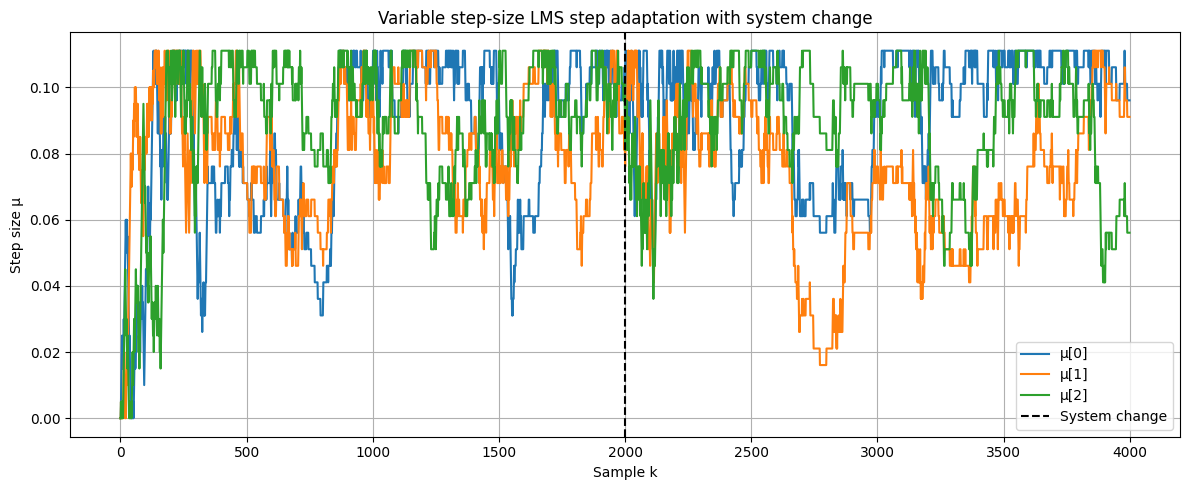

In [2]:

import numpy as np
import matplotlib.pyplot as plt

print("HELLO")

N = 4000
change_point = 2000
M = 3  # taps

MU_init = 0.005
MU_max = 0.1111
MU_min = 0.00005
rho = 0.005

h1 = np.array([0.5, 0.25, -0.3])
h2 = np.array([0.8, -0.1, -0.5])

seed = 11
noise_std = 1.0

rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)

# Unknown system changes at sample 2000
d1 = np.convolve(x, h1, mode="full")[:N]
d2 = np.convolve(x, h2, mode="full")[:N]
d = np.where(k < change_point, d1, d2)

# Initialize VSS-LMS
w = np.zeros(M)
y = np.zeros(N)
e = np.zeros(N)
mu = np.full(M, MU_init)
g_old = np.zeros(M)

w_history = np.zeros((N, M))
mu_history = np.zeros((N, M))

for k in range(M-1, N):
    x_vec = x[k-M+1:k+1][::-1]

    y[k] = np.dot(w, x_vec)
    e[k] = d[k] - y[k]

    for i in range(M):
        g = e[k] * x[k-i]

        # Update individual step sizes
        if k > M-1:
            mu[i] += rho * np.sign(g) * np.sign(g_old[i])

        mu[i] = np.clip(mu[i], MU_min, MU_max)

        # Update weights
        w[i] += 2 * mu[i] * g
        g_old[i] = g

    w_history[k] = w
    mu_history[k] = mu


# Plot weight convergence
fig, ax = plt.subplots(figsize=(12, 6))

colors = plt.cm.tab10.colors

for m in range(M):
    ax.plot(
        w_history[:, m],
        color=colors[m],
        label=f"w[{m}]"
    )

    # True coefficients, first system
    ax.hlines(
        h1[m], 0, change_point,
        color=colors[m],
        linestyle='-.',
        alpha=0.5,
        label=f"True h[{m}]"
    )

    # True coefficients, second system
    ax.hlines(
        h2[m], change_point, N-1,
        color=colors[m],
        linestyle='-.',
        alpha=0.5
    )

ax.axvline(
    change_point,
    color='black',
    linestyle='--',
    label='System change'
)

ax.set_xlabel("Sample k")
ax.set_ylabel("Weight coefficient")
ax.set_title("Variable Step-size LMS weight convergence with system change")
ax.legend(ncol=3)
ax.grid(True)

plt.tight_layout()
plt.show()


# Plot individual step sizes
fig, ax = plt.subplots(figsize=(12, 5))

for m in range(M):
    ax.plot(
        mu_history[:, m],
        color=colors[m],
        label=f"μ[{m}]"
    )

ax.axvline(
    change_point,
    color='black',
    linestyle='--',
    label='System change'
)

ax.set_xlabel("Sample k")
ax.set_ylabel("Step size μ")
ax.set_title("Variable step-size LMS step adaptation with system change")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()
